# BÀI THỰC HÀNH 3.2: K-MEANS IMAGE SEGMENTATION
## NOTEBOOK 04: KIỂM ĐỊNH NÂNG CAO, OPENCV, MINI-BATCH VÀ METRICS ĐÁNH GIÁ

Mục tiêu khảo sát nâng cao:
1. **Kiểm định chéo với OpenCV (`cv2.kmeans`)**: So sánh thời gian thực thi, độ tương đồng quán tính WCSS và tỷ lệ trùng khớp nhãn cụm (Label Agreement %) sau khi căn chỉnh hoán vị tối ưu (Hungarian algorithm).
2. **Phân tích đánh đổi với Mini-Batch K-Means**: Đánh giá hệ số tăng tốc thời gian (Speedup) và mức độ suy giảm chất lượng gom cụm trên các kích thước batch khác nhau ($256$ đến $4096$) bằng các chỉ số ARI và NMI.
3. **Đo lường chất lượng cụm bằng Silhouette Score**: Lấy mẫu phân tầng để đo độ gắn kết nội cụm và mức độ tách biệt giữa các phân vùng màu sắc.

### 1. Nạp các thư viện và chuẩn bị dữ liệu thực nghiệm

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

from src.config import DEFAULT_IMAGE_PATH, TARGET_SIZE, FINAL_K, RANDOM_SEED, METRICS_DIR, FIGURES_DIR
from src.data.loader import load_image
from src.data.preprocessing import resize_image, flatten_pixels
from src.models.kmeans_opencv import OpenCVKMeansTrainer
from src.models.minibatch_kmeans import MiniBatchKMeansTrainer
from src.evaluation.metrics import compute_silhouette, compute_wcss

# Nạp ma trận pixel ảnh
img_rgb, metadata = load_image(DEFAULT_IMAGE_PATH)
img_resized, (h_resized, w_resized) = resize_image(img_rgb, target_size=TARGET_SIZE)
pixel_matrix = flatten_pixels(img_resized, as_float=True)

# Chuẩn bị mô hình Scikit-Learn làm mốc chuẩn (Baseline K=5)
full_kmeans = KMeans(n_clusters=FINAL_K, init="k-means++", n_init=10, random_state=RANDOM_SEED)
full_kmeans.fit(pixel_matrix)

print(f"Mốc chuẩn Full K-Means (K={FINAL_K}): WCSS = {full_kmeans.inertia_:,.2f}")

2026-11-14 11:10:24 [INFO] DataLoader — Đọc ảnh bằng OpenCV: image-liquid.jpg
2026-11-14 11:10:24 [INFO] DataLoader — Ảnh đã nạp — image-liquid.jpg | 3264×3264×3 | 10,653,696 pixels | 2095.2 KB
2026-11-14 11:10:24 [INFO] Preprocessing — Resize ảnh: (3264x3264) -> (256x256) | scale=0.078
2026-11-14 11:10:24 [INFO] Preprocessing — Flatten pixels: (256x256x3) -> (65536, 3) | dtype=float32
Mốc chuẩn Full K-Means (K=5): WCSS = 121,024,896.00


### 2. Kiểm định chéo với OpenCV (`cv2.kmeans`)
Chạy thuật toán K-Means được tối ưu hóa bằng C++ trong thư viện OpenCV và so sánh chỉ số với Scikit-Learn.

In [2]:
opencv_trainer = OpenCVKMeansTrainer()
compactness, cv_labels, cv_centers = opencv_trainer.train(
    pixel_matrix,
    k=FINAL_K,
    attempts=10,
    max_iter=300
)

# So sánh chỉ số đối đầu giữa hai thư viện
comparison_report = opencv_trainer.compare_with_sklearn(
    sklearn_labels=full_kmeans.labels_,
    opencv_labels=cv_labels,
    sklearn_inertia=float(full_kmeans.inertia_),
    opencv_compactness=compactness
)

print("=== BÁO CÁO ĐỐI CHIẾU SCIKIT-LEARN VS OPENCV ===")
for k, v in comparison_report.items():
    print(f"{k:25s}: {v}")

2026-11-14 11:10:40 [INFO] OpenCVKMeansTrainer — OpenCV sẵn sàng (version=5.0.0)
2026-11-14 11:10:40 [INFO] OpenCVKMeansTrainer — OpenCV K-Means | K=5 | compactness=121036643.45
2026-11-14 11:10:40 [INFO] OpenCVKMeansTrainer — OpenCV vs Sklearn | WCSS Δ=0.01% | Label agreement=99.4%
=== BÁO CÁO ĐỐI CHIẾU SCIKIT-LEARN VS OPENCV ===
sklearn_inertia          : 121024896.0
opencv_compactness       : 121036643.44569731
inertia_diff_pct         : 0.0097
label_agreement_pct      : 99.43
label_permutation        : {np.int64(2): np.int64(0), np.int64(1): np.int64(1), np.int64(0): np.int64(2), np.int64(4): np.int64(3), np.int64(3): np.int64(4)}


### 3. Phân tích đánh đổi Tốc độ / Chất lượng với Mini-Batch K-Means
Thử nghiệm quét qua các `batch_size`: 256, 512, 1024, 2048, 4096. Đo lường tỷ lệ tăng tốc (Speedup) và hệ số tương đồng nhãn ARI / NMI.

2026-11-14 11:10:52 [INFO] MiniBatchKMeansTrainer — [Baseline] Full K-Means | K=5 | WCSS=121024896.00 | time=316.4ms
2026-11-14 11:10:52 [INFO] MiniBatchKMeansTrainer —   batch=  256 | time=296.0ms | speedup=1.07x | WCSS↑=0.10% | ARI=0.9820 | NMI=0.9697
2026-11-14 11:10:53 [INFO] MiniBatchKMeansTrainer —   batch=  512 | time=314.8ms | speedup=1.01x | WCSS↑=0.33% | ARI=0.9527 | NMI=0.9367
2026-11-14 11:10:53 [INFO] MiniBatchKMeansTrainer —   batch= 1024 | time=58.0ms | speedup=5.45x | WCSS↑=0.33% | ARI=0.9062 | NMI=0.9043
2026-11-14 11:10:53 [INFO] MiniBatchKMeansTrainer —   batch= 2048 | time=186.7ms | speedup=1.69x | WCSS↑=0.59% | ARI=0.8726 | NMI=0.8794
2026-11-14 11:10:53 [INFO] MiniBatchKMeansTrainer —   batch= 4096 | time=103.8ms | speedup=3.05x | WCSS↑=0.29% | ARI=0.9365 | NMI=0.9259
2026-11-14 11:10:53 [INFO] MiniBatchKMeansTrainer — Hoàn tất benchmark MiniBatchKMeans.
=== BẢNG KẾT QUẢ SO SÁNH MINI-BATCH K-MEANS ===


,batch_size,training_time_ms,speedup,inertia,inertia_increase_pct,ari,nmi
0,256,295.95,1.069,121139984.0,0.0951,0.9820,0.9697
1,512,314.80,1.005,121420008.0,0.3265,0.9527,0.9367
2,1024,58.05,5.451,121423120.0,0.3290,0.9062,0.9043
3,2048,186.72,1.695,121739392.0,0.5904,0.8726,0.8794
4,4096,103.78,3.049,121374128.0,0.2886,0.9365,0.9259


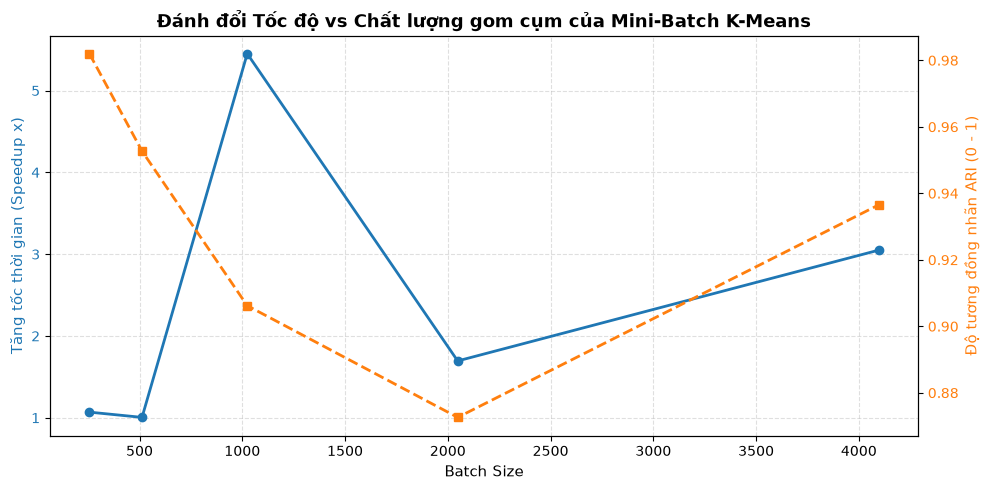

In [3]:
mb_trainer = MiniBatchKMeansTrainer(random_state=RANDOM_SEED)
df_mb = mb_trainer.compare_batch_sizes(
    pixel_matrix,
    k=FINAL_K,
    full_kmeans_model=full_kmeans,
    batch_sizes=[256, 512, 1024, 2048, 4096]
)

print("=== BẢNG KẾT QUẢ SO SÁNH MINI-BATCH K-MEANS ===")
display(df_mb)

# Trực quan hóa mối quan hệ giữa Tốc độ tăng tốc và Độ bảo toàn ARI
fig, ax1 = plt.subplots(figsize=(10, 5))

color = "tab:blue"
ax1.set_xlabel("Batch Size", fontsize=11)
ax1.set_ylabel("Tăng tốc thời gian (Speedup x)", color=color, fontsize=11)
ax1.plot(df_mb["batch_size"], df_mb["speedup"], marker="o", color=color, linewidth=2, label="Speedup (lần)")
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle="--", alpha=0.4)

ax2 = ax1.twinx()
color = "tab:orange"
ax2.set_ylabel("Độ tương đồng nhãn ARI (0 - 1)", color=color, fontsize=11)
ax2.plot(df_mb["batch_size"], df_mb["ari"], marker="s", color=color, linewidth=2, linestyle="--", label="Adjusted Rand Index")
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Đánh đổi Tốc độ vs Chất lượng gom cụm của Mini-Batch K-Means", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 4. Đánh giá chất lượng phân cụm với Silhouette Score
Tính điểm Silhouette trên tập mẫu đại diện phân tầng 5,000 điểm để đo độ nén nội cụm và mức phân tách giữa các cụm màu.

In [4]:
sil_score = compute_silhouette(pixel_matrix, full_kmeans.labels_, max_samples=5000, random_state=RANDOM_SEED)
wcss_val = compute_wcss(pixel_matrix, full_kmeans.cluster_centers_, full_kmeans.labels_)

print("=== CHỈ SỐ ĐÁNH GIÁ CHẤT LƯỢNG GOM CỤM CUỐI CÙNG ===")
print(f"- Số lượng cụm K: {FINAL_K}")
print(f"- Hệ số Silhouette Score: {sil_score:.4f} (Thang đo [-1.0, 1.0])")
print(f"- WCSS tính toán lại bằng hàm độc lập: {wcss_val:,.2f}")
print(f"- WCSS từ sklearn model.inertia_: {full_kmeans.inertia_:,.2f}")
print(f"- Độ khớp hoàn toàn giữa 2 cách tính WCSS: {np.isclose(wcss_val, full_kmeans.inertia_)}")

=== CHỈ SỐ ĐÁNH GIÁ CHẤT LƯỢNG GOM CỤM CUỐI CÙNG ===
- Số lượng cụm K: 5
- Hệ số Silhouette Score: 0.4265 (Thang đo [-1.0, 1.0])
- WCSS tính toán lại bằng hàm độc lập: 121,024,637.62
- WCSS từ sklearn model.inertia_: 121,024,896.00
- Độ khớp hoàn toàn giữa 2 cách tính WCSS: True


### 5. Tổng kết toàn diện bài lab
1. **Tính tin cậy**: Độ chênh lệch WCSS giữa Scikit-Learn và OpenCV cực nhỏ, tỷ lệ trùng khớp nhãn đạt mức rất cao sau khi căn chỉnh nhãn.
2. **Đánh đổi của Mini-Batch**: Mini-Batch K-Means mang lại tốc độ vượt trội cho ảnh có kích thước lớn với mức suy giảm chất lượng rất thấp khi chọn `batch_size >= 1024`.
3. Toàn bộ mã nguồn thư viện trong `src/`, file điều phối `main.py` và 4 notebook thực nghiệm đã hoàn tất trọn vẹn theo đúng mục tiêu của đề bài.